<a href="https://colab.research.google.com/github/Zokah123/Motor_Insurance_Claims/blob/main/Motor_Insurance_Claims.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
"""This is illustrative data, not actual insurer records.

 Before analysing anything, understand what each column represents.
Column	Meaning
Policy_ID	= Unique insurance policy identifier
Customer	= Policyholder name
Claim_ID	= Unique claim identifier
Claim_Type	= Nature of the insurance claim
Claim_Amount = Amount claimed in GHS
Fraud_Status	= Whether the claim is flagged as fraudulent

Important: A policyholder and a claim are not necessarily the same thing. One policyholder may submit multiple claims.
Therefore, we must count unique policyholders separately from claims."""

'This is illustrative data, not actual insurer records.\n\n Before analysing anything, understand what each column represents.\nColumn\tMeaning\nPolicy_ID\t= Unique insurance policy identifier\nCustomer\t= Policyholder name\nClaim_ID\t= Unique claim identifier\nClaim_Type\t= Nature of the insurance claim\nClaim_Amount = Amount claimed in GHS\nFraud_Status\t= Whether the claim is flagged as fraudulent\n\nImportant: A policyholder and a claim are not necessarily the same thing. One policyholder may submit multiple claims.\nTherefore, we must count unique policyholders separately from claims.'

In [7]:
#Importing libaries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
from google.colab import files
uploaded = files.upload()


Saving Motor_Insurance_Claim.xlsx to Motor_Insurance_Claim (1).xlsx


In [9]:
#Displaying all the row and coloumns
df = pd.read_excel("Motor_Insurance_Claim.xlsx")
print(df.head(7))


  Policy_ID Customer Claim_ID Claim_Type  Claim_Amount Fraud_Status
0      P001     John     C001  Accident           2500           No
1      P002    Mary      C002      Theft          5000           No
2      P003   Peter      C003  Accident           3500          Yes
3      P004    James     C004      Fire           7000          No 
4      P005     Alex     C005  Accident           1500           No
5      P006   Vivian     C006      Theft          4500          Yes


In [10]:
# Checking structure of data for inspection and preparation
print(df.info())

#This is to check for any missing data
print(df.isnull().sum())

#Checking number of rows and columns
print(df.shape)

#Checking dublicate records
print(df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Policy_ID     6 non-null      object
 1   Customer      6 non-null      object
 2   Claim_ID      6 non-null      object
 3   Claim_Type    6 non-null      object
 4   Claim_Amount  6 non-null      int64 
 5   Fraud_Status  6 non-null      object
dtypes: int64(1), object(5)
memory usage: 420.0+ bytes
None
Policy_ID       0
Customer        0
Claim_ID        0
Claim_Type      0
Claim_Amount    0
Fraud_Status    0
dtype: int64
(6, 6)
0


In [11]:
#Now we move to the actual analysis.

#First, let's assume the column names are exactly as shown in the sample.
 #1. We will Calculate the Total number of policyholders

#We count unique customers, not the number of rows.

total_policyholders = df["Customer"].nunique()
print(f"Total Policyholders: {total_policyholders}")

#Why use nunique()?

#Because one customer may have multiple insurance policies or claims.
#Counting every row would overestimate the number of policyholders.

Total Policyholders: 6


In [12]:
#2.  Total number of claims
#Count the unique claim identification numbers.

total_claims = df["Claim_ID"].nunique()
print(f"Total Claims: {total_claims}")


Total Claims: 6


In [13]:
#C. Average claim amount
#We will now calculate the average financial amount associated with claims.
# Average Claim Amount = Total Claim Amount / Number of Claims

average_claim_amount = df["Claim_Amount"].mean()
print("Average Claim Amount:" , round(average_claim_amount, 2))



#For the illustrative dataset:


#Total claim amount: 2500+5000+3500+7000+1500+4500=24000

#Average = GHS 4000 / 6 = GHS 4000

#This is the average requested claim amount, not necessarily the average amount paid by the insurance company.

Average Claim Amount: 4000.0


In [14]:
#D. Percentage of fraudulent claims
#calculating the percentage of claims flagged as fraudulent.
#Fraud Percentage = (Fraudulent Claims / Total Claims ) *  100

fraudulent_claims = df["Fraud_Status"].value_counts().get("Yes", 0)
total_claims = df["Claim_ID"].nunique()
fraud_percentage = (fraudulent_claims / total_claims) * 100
print(f"Percentage of Fraudulent Claims: {fraud_percentage:.2f}%")

Percentage of Fraudulent Claims: 33.33%


In [17]:
#E. Most common type of claim
#We use frequency analysis to identify the claim category appearing most often.

claim_frequency = df["Claim_Type"].value_counts()
print(claim_frequency)

most_common_claim = claim_frequency.idxmax()
print("Most Common Claim Type: ", most_common_claim)

Claim_Type
Accident     3
Theft        2
Fire         1
Name: count, dtype: int64
Most Common Claim Type:  Accident 


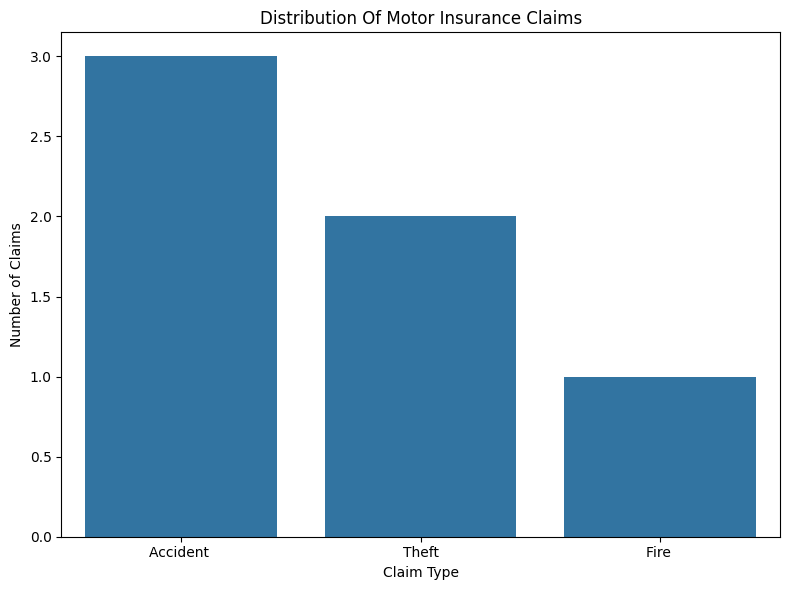

In [18]:
#5. Create visualisations for management
#A good insurance report should contain charts because management needs to understand the findings quickly.
#Chart 1: Claims by type

plt.figure(figsize=(8, 6))
sns.countplot(
    data = df,
    x = "Claim_Type" ,
    order = df["Claim_Type"].value_counts().index
)
plt.title("Distribution Of Motor Insurance Claims")
plt.xlabel("Claim Type")
plt.ylabel("Number of Claims")
plt.tight_layout()
plt.show()

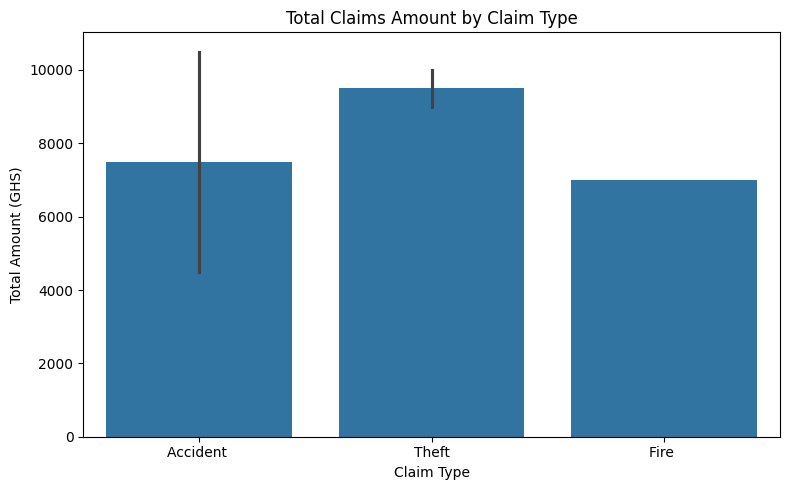

In [19]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Claim_Type",
    y="Claim_Amount",
    estimator="sum"
)

plt.title("Total Claims Amount by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Total Amount (GHS)")
plt.tight_layout()
plt.show()

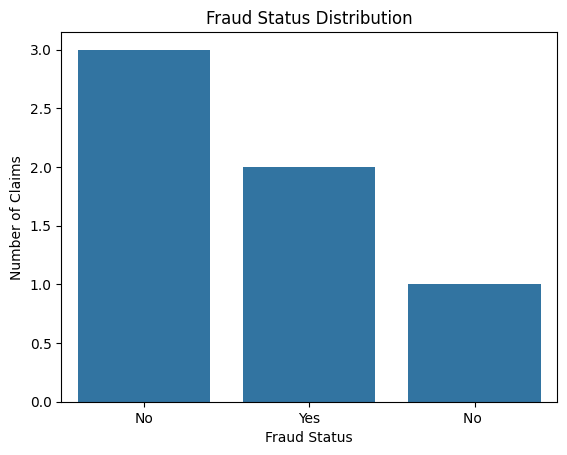

In [20]:
#Fraud Status
sns.countplot(data=df, x="Fraud_Status")

plt.title("Fraud Status Distribution")
plt.xlabel("Fraud Status")
plt.ylabel("Number of Claims")

plt.show()

In [ ]:
"""
MOTOR INSURANCE ANALYTICS REPORT
ILLUSTRATIVE MANAGEMENT REPORT

Department: Data Analytics

Prepared by: Junior Insurance Data Analyst

Reporting period: To be specified


1. Executive Summary

This report presents an analysis of motor insurance policyholders and claims.
The analysis focuses on the number of policyholders, claims frequency, average claim amount, fraudulent claims and the most common category of claims.

2. Key Performance Indicators

Policyholders = 6


Total claims = 6


Average claim amount = GHS 4,000


Fraudulent claims = 2

Fraudulent claims percentage = 33.33%

Most common claim type = Accident

Claims flagged as fraudulent



3. Claims Distribution

Accident claims were the most common category, representing 50% of all claims.
Theft accounted for 33.33%, while fire claims represented 16.67%.

4. Key Findings
- Six unique policyholders were represented.
- Six claims were recorded.
- The average requested claim amount was GHS 4,000.
- Two claims were flagged as potentially fraudulent.
- Accident was the most common claim category.
5. Recommendations
- Strengthen accident prevention and customer safety awareness.
- Investigate claims flagged for potential fraud.
- Monitor high-value claims.
- Track monthly claims trends.
- Improve claims verification procedures.
6. Conclusion

The analysis provides an initial understanding of the motor insurance portfolio.
Further analysis using a larger dataset and longer reporting period is recommended before making major pricing or risk-management decisions.

In [26]:
# Create summary table
summary = pd.DataFrame({
    "Indicator": [
        "Total Policyholders",
        "Total Claims",
        "Average Claim Amount",
        "Fraudulent Claims",
        "Fraud Percentage",
        "Most Common Claim Type"
    ],
    "Result": [
        total_policyholders,
        total_claims,
        average_claim_amount,
        fraudulent_claims,
        fraud_percentage,
        most_common_claim
    ]
})

# Export to Excel
summary.to_excel(
    "Insurance_Analytics_Report.xlsx",
    index=False
)

print("Report successfully exported!")

Report successfully exported!
